<a href="https://colab.research.google.com/github/Ladecodes1/formative-3-group/blob/main/part4_gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 4: Gradient Descent in Code
Goal: turn the Part 3 manual calculations into Python and check that the code gives the same numbers.
Model: y = m₁x₁ + m₂x₂ + b, written in matrix form as ŷ = Xm + b.
Settings agreed by the group: learning rate α = 0.005, 3 updates, one shared bias b, rounded to 4 decimal places.

## Step 1: Imports and data
Everything is stored as NumPy arrays so the maths uses matrix multiplication, as the brief requires.
Each row of X is one data point and each column is one feature (x₁, x₂).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

X = np.array([[1, 3],
              [4, 10]], dtype=float)
y = np.array([5, 6], dtype=float)

m_initial = np.array([-1, 2], dtype=float)
b_initial = np.array([1, 1], dtype=float)  # one shared bias, written once per data point

LEARNING_RATE = 0.005
N_UPDATES = 3
n = len(y)

print("X =\n", X)
print("y =", y)
print("Initial m =", m_initial)
print("Initial b =", b_initial)
print("Learning rate:", LEARNING_RATE, "| Updates:", N_UPDATES, "| Data points n:", n)

X =
 [[ 1.  3.]
 [ 4. 10.]]
y = [5. 6.]
Initial m = [-1.  2.]
Initial b = [1. 1.]
Learning rate: 0.005 | Updates: 3 | Data points n: 2


## Step 2: Prediction and cost
`predict` computes ŷ = Xm + b with one matrix multiplication.
`mse` computes the cost J = (1/n) · eᵀe, where e = ŷ − y is the error for each data point.

In [2]:
def predict(X, m, b):
    """Predicted values: y_hat = Xm + b."""
    return X @ m + b


def mse(X, y, m, b):
    """Mean squared error: J = (1/n) * e^T e, where e = y_hat - y."""
    errors = predict(X, m, b) - y
    return (errors @ errors) / len(y)


y_hat = predict(X, m_initial, b_initial)
print("Predictions y_hat:", y_hat)
print("Errors y_hat - y: ", y_hat - y)
print("Cost J:           ", mse(X, y, m_initial, b_initial))

Predictions y_hat: [ 6. 17.]
Errors y_hat - y:  [ 1. 11.]
Cost J:            61.0


These match Update 1 in the Part 3 manual calculations: ŷ = [6, 17], e = [1, 11], J = 61.

## Step 3: Derivatives with SciPy
`derivative` accepts any equation (a Python function of the parameters) and uses SciPy's `approx_fprime` to compute its derivative numerically.
The equation we pass in is the cost J(m₁, m₂, b). The bias is one shared value, so it is a single parameter here.

In [3]:
def derivative(equation, params):
    """Numerical derivative of an equation with respect to each of its parameters (SciPy)."""
    return approx_fprime(params, equation)


def cost_equation(params):
    """The cost J as an equation of the parameters [m1, m2, b]."""
    m, b = params[:2], np.full(n, params[2])
    return mse(X, y, m, b)


params_initial = np.array([*m_initial, b_initial[0]])
scipy_gradient = derivative(cost_equation, params_initial)

print("SciPy dJ/dm1, dJ/dm2, dJ/db:", np.round(scipy_gradient, 4))

SciPy dJ/dm1, dJ/dm2, dJ/db: [ 45. 113.  12.]


We check SciPy against the formulas derived by hand in Part 3:
∂J/∂m = (2/n) · Xᵀ(ŷ − y) and ∂J/∂b = (2/n) · Σ(ŷ − y).

In [4]:
def gradients(X, y, m, b):
    """Gradients from the Part 3 derivation: dJ/dm = (2/n) X^T e and dJ/db = (2/n) sum(e)."""
    errors = predict(X, m, b) - y
    grad_m = (2 / len(y)) * X.T @ errors
    grad_b = (2 / len(y)) * errors.sum()
    return grad_m, grad_b


grad_m, grad_b = gradients(X, y, m_initial, b_initial)
print("Formula dJ/dm:", grad_m, "| dJ/db:", grad_b)
print("SciPy agrees with the formula:", np.allclose(scipy_gradient, [*grad_m, grad_b], atol=1e-4))

Formula dJ/dm: [ 45. 113.] | dJ/db: 12.0
SciPy agrees with the formula: True


Both give ∂J/∂m = [45, 113] and ∂J/∂b = 12, matching Update 1 in Part 3.

## Step 4: Gradient descent updates
Each update follows the same four steps as the manual calculations:
1. Predictions ŷ = Xm + b
2. Errors e = ŷ − y and cost J
3. Gradients ∂J/∂m and ∂J/∂b
4. New values: m − α · ∂J/∂m and b − α · ∂J/∂b

As agreed for Part 3, the new m and b are rounded to 4 decimal places after each update, so the code reproduces the handwritten numbers exactly.
SciPy re-checks the gradients at every update.

In [5]:
DECIMALS = 4


def update_step(X, y, m, b, learning_rate):
    """One gradient descent update, printing every intermediate result."""
    y_hat = predict(X, m, b)
    errors = y_hat - y
    cost = mse(X, y, m, b)
    grad_m, grad_b = gradients(X, y, m, b)
    scipy_check = np.allclose(derivative(cost_equation, np.array([*m, b[0]])), [*grad_m, grad_b], atol=1e-4)

    m_new = np.round(m - learning_rate * grad_m, DECIMALS)
    b_new = np.round(b - learning_rate * grad_b, DECIMALS)

    print("  1. Predictions y_hat:", np.round(y_hat, 6))
    print("  2. Errors e:         ", np.round(errors, 6), "| Cost J:", round(cost, 6))
    print("  3. dJ/dm:            ", np.round(grad_m, 6), "| dJ/db:", round(grad_b, 6), "| SciPy agrees:", scipy_check)
    print("  4. New m:            ", m_new, "| New b:", b_new)
    return m_new, b_new


m, b = m_initial, b_initial
m_history, b_history, cost_history = [m], [b], [mse(X, y, m, b)]

for update in range(1, N_UPDATES + 1):
    print(f"Update {update}  (start: m = {m}, b = {b})")
    m, b = update_step(X, y, m, b, LEARNING_RATE)
    m_history.append(m)
    b_history.append(b)
    cost_history.append(mse(X, y, m, b))
    print()

Update 1  (start: m = [-1.  2.], b = [1. 1.])
  1. Predictions y_hat: [ 6. 17.]
  2. Errors e:          [ 1. 11.] | Cost J: 61.0
  3. dJ/dm:             [ 45. 113.] | dJ/db: 12.0 | SciPy agrees: True
  4. New m:             [-1.225  1.435] | New b: [0.94 0.94]

Update 2  (start: m = [-1.225  1.435], b = [0.94 0.94])
  1. Predictions y_hat: [ 4.02 10.39]
  2. Errors e:          [-0.98  4.39] | Cost J: 10.11625
  3. dJ/dm:             [16.58 40.96] | dJ/db: 3.41 | SciPy agrees: True
  4. New m:             [-1.3079  1.2302] | New b: [0.923 0.923]

Update 3  (start: m = [-1.3079  1.2302], b = [0.923 0.923])
  1. Predictions y_hat: [3.3057 7.9934]
  2. Errors e:          [-1.6943  1.9934] | Cost J: 3.422148
  3. dJ/dm:             [ 6.2793 14.8511] | dJ/db: 0.2991 | SciPy agrees: True
  4. New m:             [-1.3393  1.1559] | New b: [0.9215 0.9215]



Every number above matches Updates 1–3 in the Part 3 manual calculations. The summary below is the same table as in Part 3.

In [6]:
print(f"{'After':<10}{'m1':>9}{'m2':>9}{'b':>9}{'J':>10}")
for step, (m_k, b_k, cost_k) in enumerate(zip(m_history, b_history, cost_history)):
    label = "Start" if step == 0 else f"Update {step}"
    print(f"{label:<10}{m_k[0]:>9.4f}{m_k[1]:>9.4f}{b_k[0]:>9.4f}{cost_k:>10.4f}")

After            m1       m2        b         J
Start       -1.0000   2.0000   1.0000   61.0000
Update 1    -1.2250   1.4350   0.9400   10.1163
Update 2    -1.3079   1.2302   0.9230    3.4221
Update 3    -1.3393   1.1559   0.9215    2.5323


## Step 5: Predictions with the final m and b
We reuse `predict` and `mse` with the values left after the last update and compare them with the starting point.

In [7]:
m_final, b_final = m_history[-1], b_history[-1]
y_hat_final = predict(X, m_final, b_final)

print("Final m:", m_final, "| Final b:", b_final)
print()
print(f"{'Point':<8}{'Target y':>10}{'Start y_hat':>13}{'Final y_hat':>13}")
for i, (target, start, final) in enumerate(zip(y, predict(X, m_initial, b_initial), y_hat_final), start=1):
    print(f"{i:<8}{target:>10.4f}{start:>13.4f}{final:>13.4f}")
print()
print(f"Cost J: {cost_history[0]:.4f} at the start -> {cost_history[-1]:.4f} after {N_UPDATES} updates "
      f"({1 - cost_history[-1] / cost_history[0]:.0%} lower)")

Final m: [-1.3393  1.1559] | Final b: [0.9215 0.9215]

Point     Target y  Start y_hat  Final y_hat
1           5.0000       6.0000       3.0499
2           6.0000      17.0000       7.1233

Cost J: 61.0000 at the start -> 2.5323 after 3 updates (96% lower)


The final predictions [3.0499, 7.1233] are much closer to the targets [5, 6] overall: J fell from 61 to 2.5323.
Point 2 improved the most (error 11 → 1.12) because its large x₂ = 10 gave it the largest gradient.
Point 1 actually moved further from its target (error 1 → −1.95): gradient descent lowers the total cost, so it accepts a small loss on one point for a big gain on the other.

## Step 6: Plots
Both plots read from the history recorded during the updates, so they always match the printed numbers.
`style_axes` keeps the two plots consistent without repeating the same settings.

In [8]:
ITERATIONS = list(range(len(cost_history)))
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def style_axes(ax, title, ylabel):
    """Shared look for both plots: left-aligned title, light grid, one tick per iteration."""
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Iteration (0 = starting values)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(ITERATIONS)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

### How m and b change over iterations

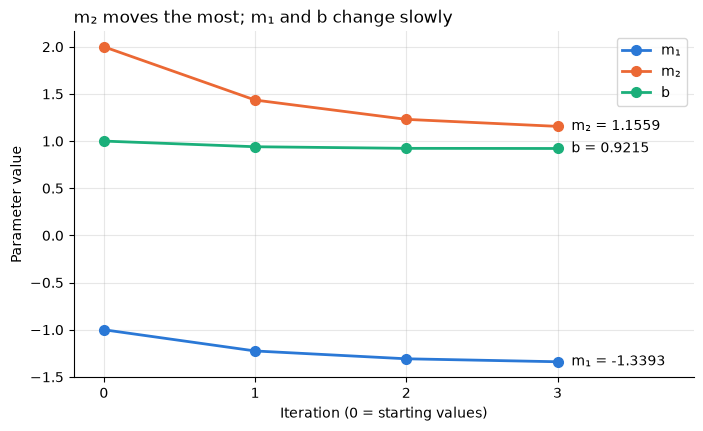

In [9]:
parameters = {
    "m₁": [m_k[0] for m_k in m_history],
    "m₂": [m_k[1] for m_k in m_history],
    "b": [b_k[0] for b_k in b_history],
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, values), color in zip(parameters.items(), COLORS):
    ax.plot(ITERATIONS, values, marker="o", markersize=7, linewidth=2, color=color, label=name)
    ax.annotate(f"{name} = {values[-1]:.4f}", (ITERATIONS[-1], values[-1]),
                xytext=(10, 0), textcoords="offset points", va="center")
style_axes(ax, "m₂ moves the most; m₁ and b change slowly", "Parameter value")
ax.set_xlim(-0.2, ITERATIONS[-1] + 0.9)
ax.legend(loc="upper right")
plt.show()

### How the error changes over iterations

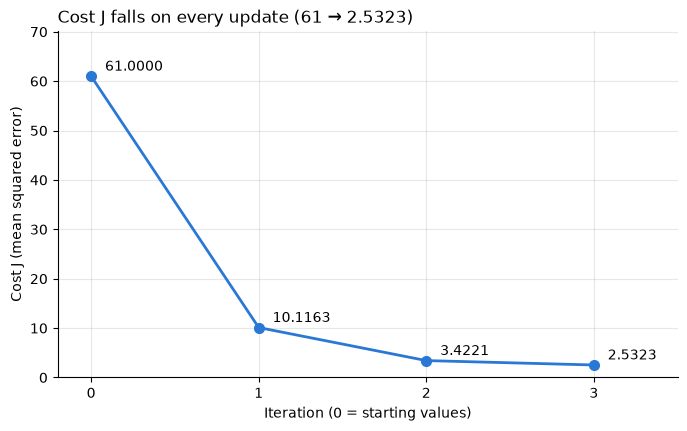

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ITERATIONS, cost_history, marker="o", markersize=7, linewidth=2, color=COLORS[0])
for k, cost in zip(ITERATIONS, cost_history):
    ax.annotate(f"{cost:.4f}", (k, cost), xytext=(10, 4), textcoords="offset points", ha="left")
style_axes(ax, f"Cost J falls on every update ({cost_history[0]:.0f} → {cost_history[-1]:.4f})", "Cost J (mean squared error)")
ax.set_ylim(0, max(cost_history) * 1.15)
ax.set_xlim(-0.2, ITERATIONS[-1] + 0.5)
plt.show()